In [1]:
# Import TensorFlow for deep learning and image processing.
import tensorflow as tf

# Import NumPy for numerical operations.
import numpy as np

# Import Matplotlib for plotting images and training curves.
import matplotlib.pyplot as plt

# Import MobileNetV2's model-specific preprocessing function.
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Import MobileNetV2 for transfer learning.
from tensorflow.keras.applications import MobileNetV2

# Import Keras layers and model-building utilities.
from tensorflow.keras import layers, models

# Import the Adam optimizer.
from tensorflow.keras.optimizers import Adam

# Import class-weight calculation utilities.
from sklearn.utils.class_weight import compute_class_weight

# Import Path for convenient directory handling.
from pathlib import Path

# Set the image height and width.
IMG_SIZE = (224, 224)

# Set the number of images processed per batch.
BATCH_SIZE = 32

# Set the number of disease/healthy classes.
NUM_CLASSES = 33

# Set a seed to improve reproducibility.
SEED = 42

# Define the training folder path in Google Drive.
TRAIN_DIR = "/content/drive/MyDrive/plant disease dataset/train"

# Define the validation folder path in Google Drive.
VAL_DIR = "/content/drive/MyDrive/plant disease dataset/validation"

# Define the testing folder path in Google Drive.
TEST_DIR = "/content/drive/MyDrive/plant disease dataset/test"

# Print the configuration.
print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

TensorFlow version: 2.21.0
Image size: (224, 224)
Batch size: 32
Number of classes: 33


Resize all images to the same size,Convert images to 3-channel RGB,Pixel normalization for MobileNetV2,Encoding class labels in train test and validation make sure that it applies for all and checks wether all labels are present or not


In [ ]:
# Load the training images from their class folders.
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Load validation images without shuffling.
val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Load test images without shuffling.
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Store the class names in TensorFlow's assigned order.
class_names = train_dataset.class_names

# Verify that all three datasets use the same class mapping.
assert class_names == val_dataset.class_names
assert class_names == test_dataset.class_names

# Verify that the dataset contains the expected number of classes.
assert len(class_names) == NUM_CLASSES

# Apply MobileNetV2 preprocessing to training images.
train_dataset = train_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Apply identical preprocessing to validation images.
val_dataset = val_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Apply identical preprocessing to test images.
test_dataset = test_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Prefetch batches to improve data-loading efficiency.
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

# Display the detected classes.
print("Number of classes:", len(class_names))
print("Class names:", class_names)

# Confirm that preprocessing is complete.
print("Data loading and preprocessing completed.")

Found 27986 files belonging to 33 classes.
Found 6000 files belonging to 33 classes.
Found 6014 files belonging to 33 classes.
Number of classes: 33
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Viru

Verifing the preprocessed data

In [ ]:
# Retrieve one batch from the training dataset.
for images, labels in train_dataset.take(1):

    # Display the shape of the image batch.
    print("Image batch shape:", images.shape)

    # Display the shape of the labels.
    print("Label batch shape:", labels.shape)

    # Display the minimum pixel value.
    print("Minimum pixel value:", tf.reduce_min(images).numpy())

    # Display the maximum pixel value.
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    # Display the first 10 integer labels.
    print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0
First 10 labels: [21 32 30 19 28 30 30  6 17 30]


calculating class weights due to class imbalance class weights are calculated and assigned instead of random weights

In [6]:
# Import the operating-system utilities for working with folders.
import os

# Import NumPy for storing the labels in an array.
import numpy as np

# Create an empty list to store the integer label of each image.
train_labels_list = []

# Loop through every class in the same order used by TensorFlow.
for class_id, class_name in enumerate(class_names):

    # Construct the path to the current class folder.
    class_dir = os.path.join(TRAIN_DIR, class_name)

    # Count image files directly inside this class folder.
    image_count = sum(
        1 for filename in os.listdir(class_dir)
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".gif"))
    )

    # Add the class label once for every image in this folder.
    train_labels_list.extend([class_id] * image_count)

# Convert the collected labels into a NumPy array.
train_labels = np.array(train_labels_list, dtype=np.int32)

# Display the number of labels collected.
print("Total training labels:", len(train_labels))

Total training labels: 27986


In [7]:
# Find the class IDs present in the collected labels.
unique_classes = np.unique(train_labels)

# Calculate balanced class weights using the training labels.
weights = compute_class_weight(
    class_weight="balanced",
    classes=unique_classes,
    y=train_labels
)

# Map each class ID to its calculated weight.
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(unique_classes, weights)
}

# Display the number of class weights and their values.
print("Number of class weights:", len(class_weights))
print(class_weights)

Number of class weights: 33
{0: 1.923039923039923, 1: 1.95405669599218, 2: 4.4169823232323235, 3: 0.7380858190257668, 4: 1.152256258234519, 5: 1.4205370285772296, 6: 2.3622858107537774, 7: 1.0168592398808227, 8: 1.2308571931213441, 9: 1.0431249767043125, 10: 1.0267077555213149, 11: 0.8760956674179815, 12: 1.1262425047285605, 13: 2.865069615069615, 14: 0.5277290641323, 15: 3.3653198653198655, 16: 1.216729707404026, 17: 0.8201746673700252, 18: 1.2115151515151514, 19: 1.2115151515151514, 20: 8.000571755288737, 21: 1.0928616057482037, 22: 2.6584971976821508, 23: 0.5699332029977191, 24: 1.2115151515151514, 25: 0.6343011264477233, 26: 1.2733642733642734, 27: 0.6844718370142099, 28: 0.7229843188922472, 29: 0.8636055051533666, 30: 0.22620981756751296, 31: 3.2492743527226287, 32: 0.7619592147894034}


In [ ]:
# Import MobileNetV2 and the required Keras layers.
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Define the pretrained MobileNetV2 feature extractor.
base_model = MobileNetV2(
    weights="imagenet",            # Load pretrained ImageNet weights.
    include_top=False,             # Remove the original 1,000-class classifier.
    input_shape=(224, 224, 3)      # Expect RGB images of size 224 × 224.
)

# Freeze the pretrained layers during initial training.
base_model.trainable = False

# Define the input for images already preprocessed by your dataset pipeline.
inputs = layers.Input(shape=(224, 224, 3))

# Extract visual features using the frozen MobileNetV2 base.
x = base_model(inputs, training=False)

# Convert feature maps into a single feature vector per image.
x = layers.GlobalAveragePooling2D()(x)

# Apply dropout to help reduce overfitting.
x = layers.Dropout(0.30)(x)

# Predict probabilities for the 33 plant disease classes.
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

# Combine all layers into the final classification model.
model_mobilenet = models.Model(inputs=inputs, outputs=outputs)

# Display the model architecture and parameter counts.
model_mobilenet.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 33)             │        42,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,300,257 (8.77 MB)

 Trainable params: 42,273 (165.13 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Import the Adam optimizer.
from tensorflow.keras.optimizers import Adam

# Configure the model for training.
model_mobilenet.compile(
    optimizer=Adam(learning_rate=0.001),       # Set the learning rate.
    loss="sparse_categorical_crossentropy",    # Use integer class labels.
    metrics=["accuracy"]                       # Track classification accuracy.
)

# Confirm that the model is compiled.
print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
# Import the callback base class from Keras.
from tensorflow.keras.callbacks import Callback

# Define a callback that prints the start and end of validation.
class ValidationProgress(Callback):

    # This method runs immediately before validation starts.
    def on_test_begin(self, logs=None):
        print("\nValidation has started.")

    # This method runs after each validation batch finishes.
    def on_test_batch_end(self, batch, logs=None):
        # Print progress every 20 batches and on the last batch.
        if (batch + 1) % 20 == 0 or (batch + 1) == len(val_dataset):
            print(f"Validation batches completed: {batch + 1}/{len(val_dataset)}")

    # This method runs when validation has finished.
    def on_test_end(self, logs=None):
        print("Validation has finished.")

In [ ]:
# Import the callbacks used to control training and save the model.
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop training if validation loss fails to improve for 3 epochs.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Save the model whenever validation loss reaches a new minimum.
model_checkpoint = ModelCheckpoint(
    filepath="/content/drive/MyDrive/best_plant_disease_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Train the model using the training dataset.
history = model_mobilenet.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    class_weight=class_weights,
    #callbacks=[model_checkpoint]#,ValidationProgress()]
)

Epoch 1/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 106s 107ms/step - accuracy: 0.8009 - loss: 0.7061 - val_accuracy: 0.8930 - val_loss: 0.3313
Epoch 2/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 77s 88ms/step - accuracy: 0.9044 - loss: 0.2808 - val_accuracy: 0.9128 - val_loss: 0.2606
Epoch 3/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 77s 88ms/step - accuracy: 0.9211 - loss: 0.2234 - val_accuracy: 0.9282 - val_loss: 0.2226
Epoch 4/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 79s 90ms/step - accuracy: 0.9300 - loss: 0.1936 - val_accuracy: 0.9267 - val_loss: 0.2179
Epoch 5/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 82s 90ms/step - accuracy: 0.9337 - loss: 0.1770 - val_accuracy: 0.9362 - val_loss: 0.1896
Epoch 6/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 82s 93ms/step - accuracy: 0.9399 - loss: 0.1553 - val_accuracy: 0.9387 - val_loss: 0.1870
Epoch 7/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 78s 89ms/step - accuracy: 0.9430 - loss: 0.1488 - val_accuracy: 0.9420 - val_loss: 0.1807
Epoch 8/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 88s 101ms/step - accuracy: 0.9443 - loss: 0.1419

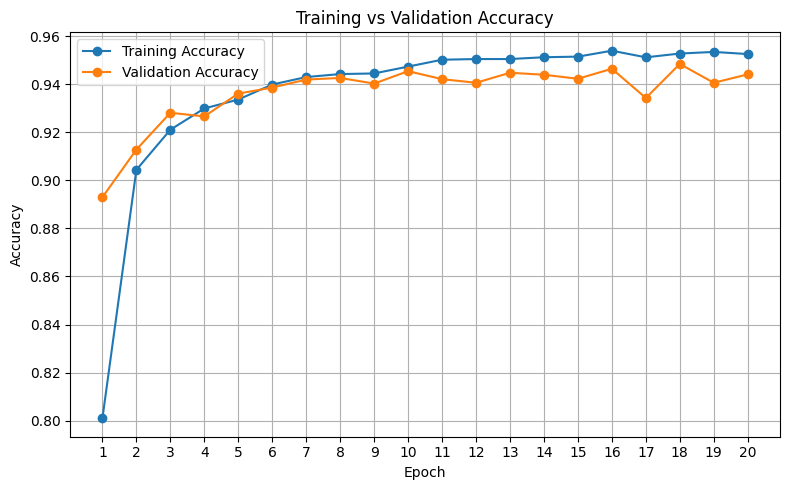

In [ ]:
# Import Matplotlib for plotting graphs.
import matplotlib.pyplot as plt

# Create a list of epoch numbers starting from 1.
epochs = range(1, len(history.history["accuracy"]) + 1)

# Create a new figure for the accuracy plot.
plt.figure(figsize=(8, 5))

# Plot the training accuracy for each epoch.
plt.plot(epochs, history.history["accuracy"], marker="o", label="Training Accuracy")

# Plot the validation accuracy for each epoch.
plt.plot(epochs, history.history["val_accuracy"], marker="o", label="Validation Accuracy")

# Add a title and axis labels.
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

# Display epoch numbers as x-axis ticks.
plt.xticks(list(epochs))

# Display the legend and grid.
plt.legend()
plt.grid(True)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

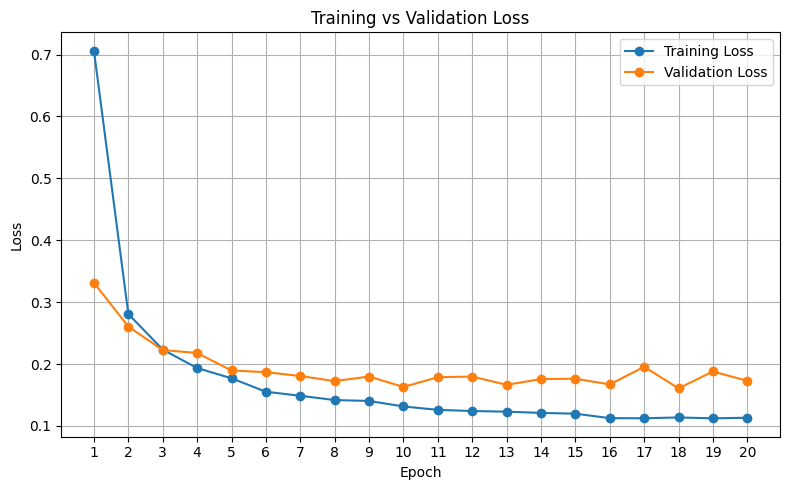

In [ ]:
# Create a new figure for the loss plot.
plt.figure(figsize=(8, 5))

# Plot the training loss for each epoch.
plt.plot(epochs, history.history["loss"], marker="o", label="Training Loss")

# Plot the validation loss for each epoch.
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation Loss")

# Add a title and axis labels.
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

# Display epoch numbers as x-axis ticks.
plt.xticks(list(epochs))

# Display the legend and grid.
plt.legend()
plt.grid(True)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

In [ ]:

# Save the current model to Google Drive in Keras format.
model_mobilenet.save("/content/drive/MyDrive/my_plant_disease_model.keras")

# Confirm the save operation.
print("Model saved successfully.")

Model saved successfully.


In [ ]:
# Import TensorFlow's model-loading functionality.
import tensorflow as tf

# Load the best model saved during training.
mobilenet_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/my_plant_disease_model.keras"
)

# Evaluate the best model on previously unseen test images.
test_loss, test_accuracy = model_mobilenet.evaluate(test_dataset)

# Print the final evaluation metrics.
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy percentage: {test_accuracy * 100:.2f}%")

188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 98ms/step - accuracy: 0.9463 - loss: 0.1773
Test loss: 0.1773
Test accuracy: 0.9463
Test accuracy percentage: 94.63%


In [ ]:
# Import the classification report function.
from sklearn.metrics import classification_report

# Collect the actual integer labels from the test dataset.
y_true = np.concatenate([
    labels.numpy() for _, labels in test_dataset
])

# Predict probabilities for each test image.
y_prob = mobilenet_model.predict(test_dataset)

# Select the class with the highest predicted probability.
y_pred = np.argmax(y_prob, axis=1)

# Print precision, recall, F1-score, and support for all classes.
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0
))

188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step
                                               precision    recall  f1-score   support

                           Apple___Apple_scab     0.9000    0.9474    0.9231        95
                            Apple___Black_rot     0.9691    1.0000    0.9843        94
                     Apple___Cedar_apple_rust     0.9756    0.9524    0.9639        42
                              Apple___healthy     0.9959    0.9839    0.9899       249
                      Cherry___Powdery_mildew     1.0000    0.9937    0.9968       158
                             Cherry___healthy     1.0000    0.9922    0.9961       129
   Corn___Cercospora_leaf_spot Gray_leaf_spot     0.7778    0.8182    0.7975        77
                           Corn___Common_rust     0.9944    1.0000    0.9972       179
                  Corn___Northern_Leaf_Blight     0.9021    0.8716    0.8866       148
                               Corn___healthy     0.9943    1.0000    0.9972       175

188/188 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step


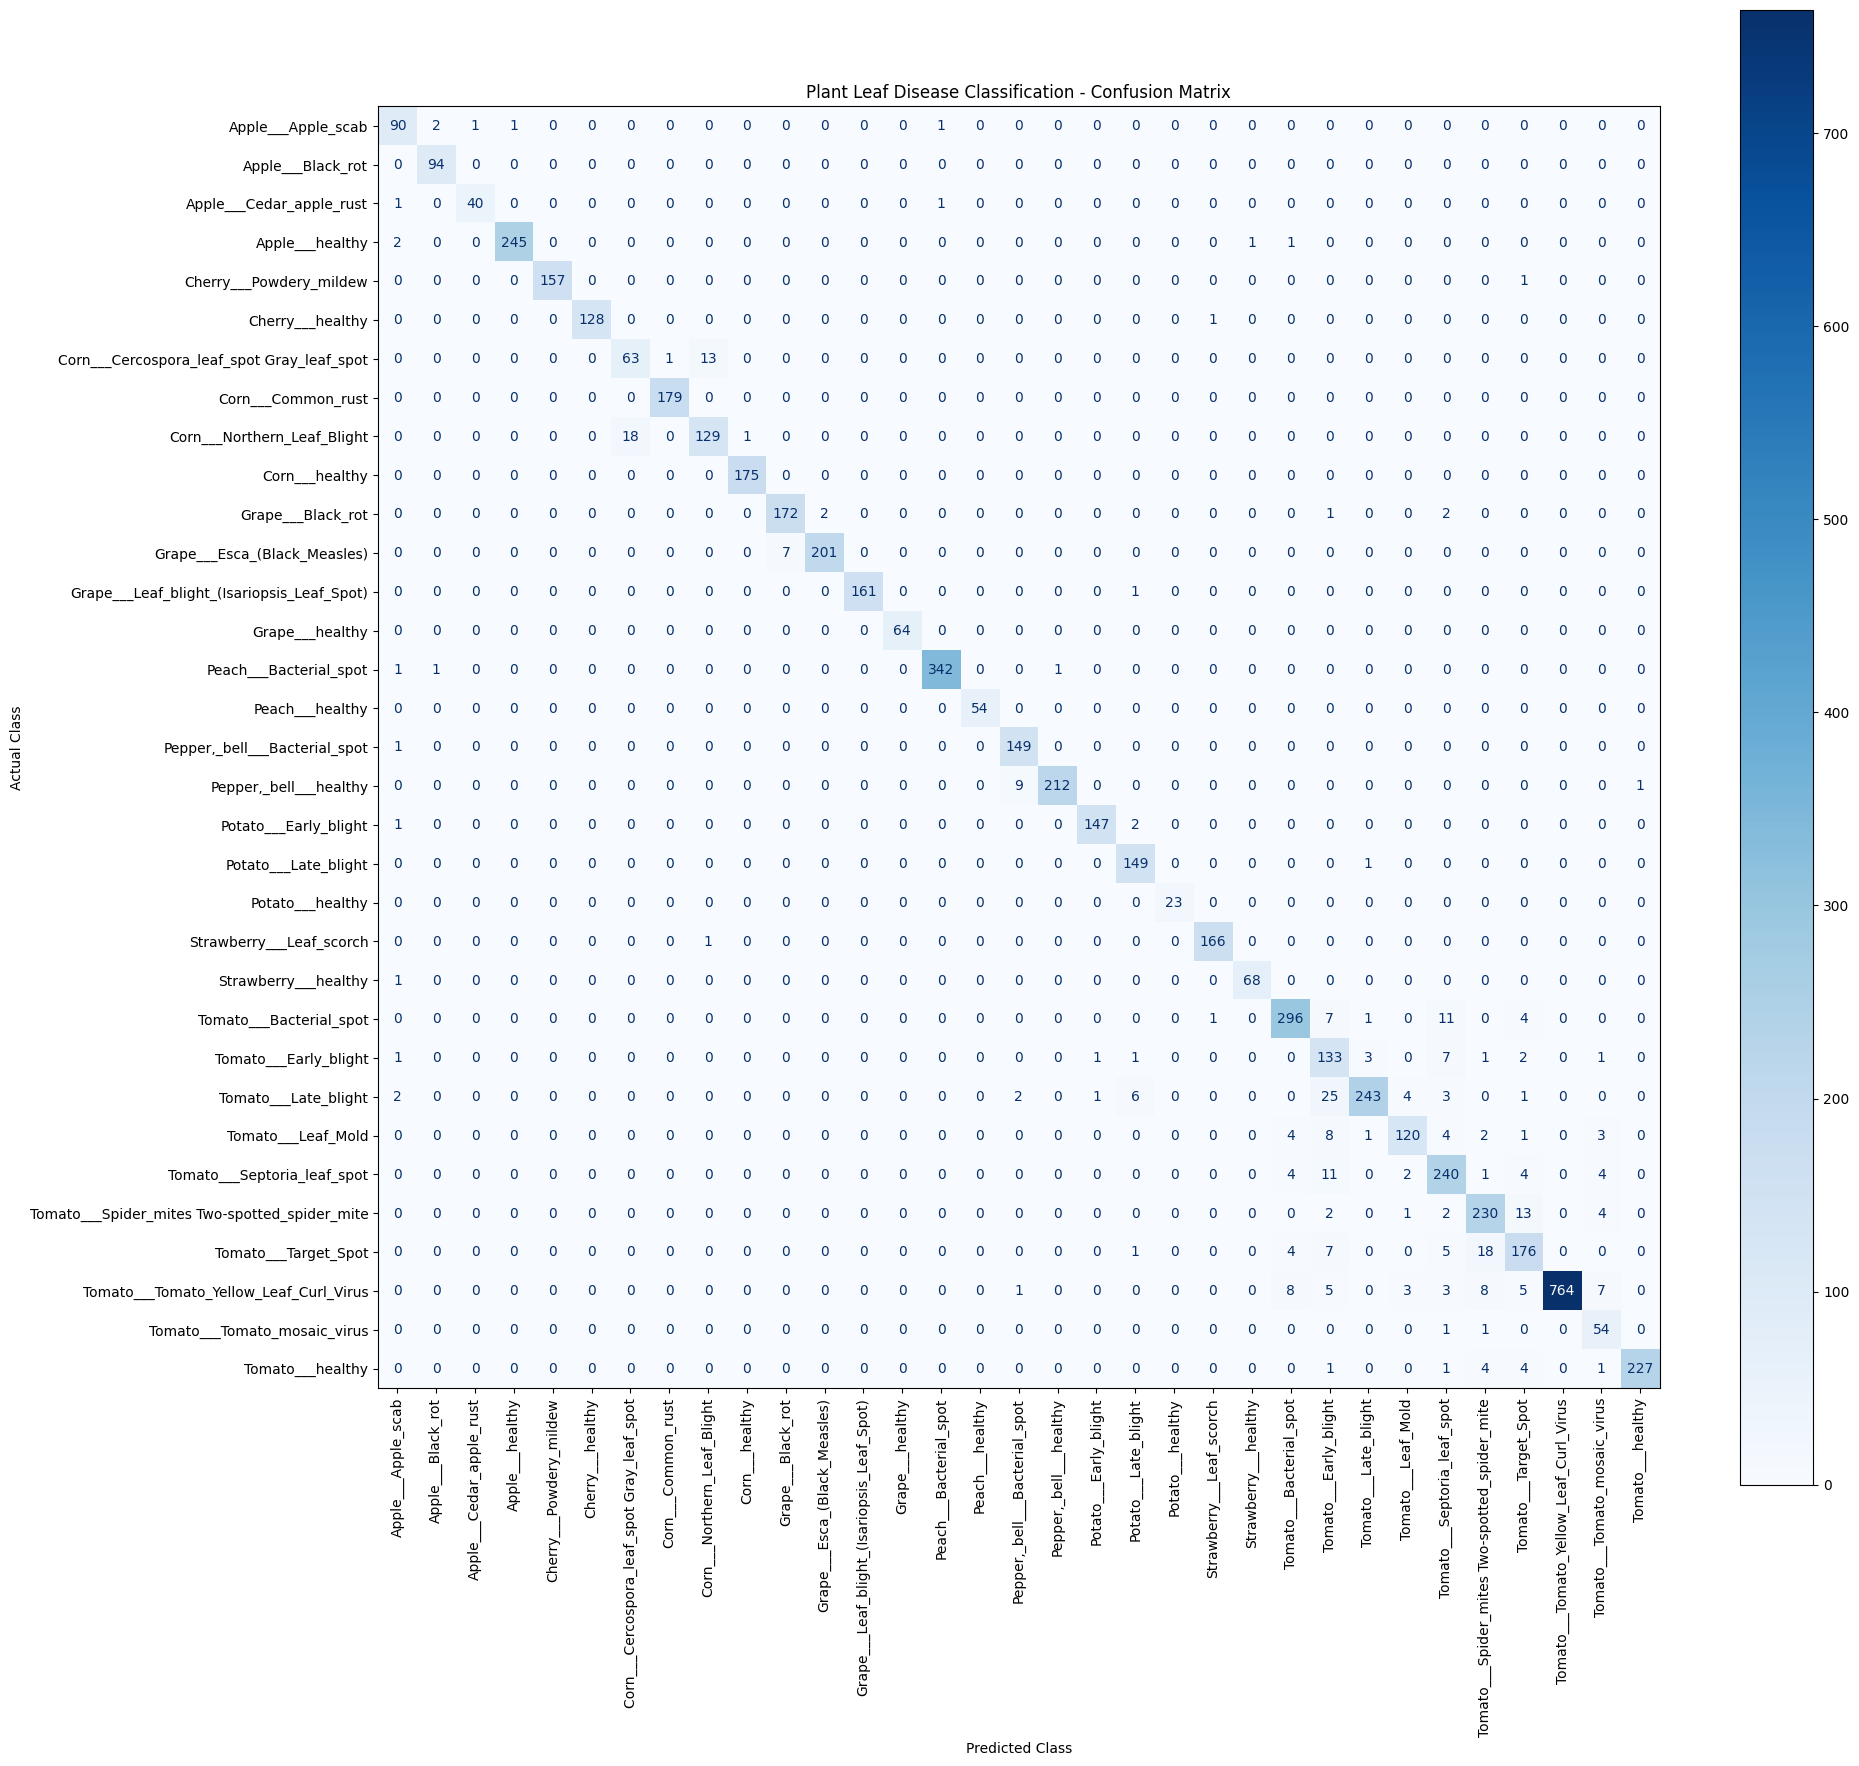

In [ ]:
# Import NumPy for numerical operations.
import numpy as np

# Import Matplotlib for displaying the confusion matrix.
import matplotlib.pyplot as plt

# Import the confusion matrix calculation function.
from sklearn.metrics import confusion_matrix

# Import the ConfusionMatrixDisplay visualization utility.
from sklearn.metrics import ConfusionMatrixDisplay

# Collect the actual integer labels from all test batches.
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

# Predict class probabilities for every test image.
y_prob = mobilenet_model.predict(test_dataset)

# Select the class with the highest predicted probability.
y_pred = np.argmax(y_prob, axis=1)

# Calculate the confusion matrix using all 33 class labels.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

# Create a large figure so the 33 class labels are more readable.
fig, ax = plt.subplots(figsize=(20, 18))

# Display the confusion matrix with class names.
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

# Draw the matrix and rotate the labels for readability.
display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

# Add a descriptive title.
plt.title("Plant Leaf Disease Classification - Confusion Matrix")

# Label both axes.
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Adjust spacing to prevent label overlap.
plt.tight_layout()

# Display the confusion matrix.
plt.show()

In [ ]:
# Import the Google Colab file upload utility.
from google.colab import files

# Open a file picker to upload one or more leaf images.
uploaded = files.upload()

# Display the names of the uploaded files.
print("Uploaded files:", list(uploaded.keys()))

Saving hi.jpg to hi (1).jpg
Uploaded files: ['hi (1).jpg']


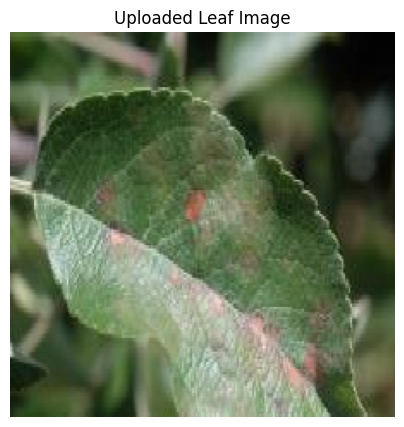

Predicted class: Apple___Apple_scab
Confidence: 82.43%


In [ ]:
# Import the image-processing utilities from TensorFlow.
from tensorflow.keras.utils import load_img, img_to_array

# Import NumPy for array operations.
import numpy as np

# Import Matplotlib for displaying the uploaded image.
import matplotlib.pyplot as plt

# Import MobileNetV2 preprocessing.
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Select the first uploaded image.
image_path = next(iter(uploaded.keys()))

# Load the image and resize it to the model's expected input size.
img = load_img(
    image_path,
    target_size=(224, 224),
    color_mode="rgb"
)

# Convert the image into a numerical array.
img_array = img_to_array(img)

# Add a batch dimension because the model expects a batch of images.
img_array = np.expand_dims(img_array, axis=0)

# Apply MobileNetV2 preprocessing exactly once.
img_array = preprocess_input(img_array)

# Predict probabilities for all 33 disease classes.
predictions = mobilenet_model.predict(img_array, verbose=0)

# Find the index of the class with the highest predicted probability.
predicted_index = np.argmax(predictions[0])

# Convert the predicted index into its class name.
predicted_class = class_names[predicted_index]

# Extract the confidence score of the predicted class.
confidence = predictions[0][predicted_index] * 100

# Display the uploaded image.
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("Uploaded Leaf Image")
plt.show()

# Print the predicted disease and confidence.
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

In [ ]:
# Find the indices of the three highest predicted probabilities.
top_indices = np.argsort(predictions[0])[-3:][::-1]

# Print the top three predicted classes and their confidence scores.
print("Top 3 predictions:")

for index in top_indices:
    print(f"{class_names[index]}: {predictions[0][index] * 100:.2f}%")

Top 3 predictions:
Apple___Apple_scab: 82.43%
Strawberry___Leaf_scorch: 9.76%
Corn___Northern_Leaf_Blight: 7.81%


as the mobile net is a light weight modle which is good but it struggles with some of the classes in the dataset so i am moving to NASNET

Data preprocessing for NASNET model

In [2]:
import tensorflow as tf
from tensorflow.keras.applications.nasnet import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load the original training images
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True,
    seed=42
)

# Preserve the class-index mapping
class_names = train_dataset.class_names

# Load validation and test datasets without shuffling
val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Confirm that all splits use the same class ordering
assert class_names == val_dataset.class_names
assert class_names == test_dataset.class_names

# Apply NASNetMobile preprocessing exactly once
train_dataset = train_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Prefetch batches to improve input pipeline throughput
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)

Found 27986 files belonging to 33 classes.
Found 6000 files belonging to 33 classes.
Found 6014 files belonging to 33 classes.
Number of classes: 33


In [3]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import NASNetMobile

# Load NASNetMobile with pretrained ImageNet weights
# Exclude its original 1000-class classification head
base_model = NASNetMobile(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained feature extractor
base_model.trainable = False

# Define the model input
inputs = layers.Input(shape=(224, 224, 3))

# Extract features using the frozen NASNetMobile base
x = base_model(inputs, training=False)

# Convert feature maps into a single feature vector
x = layers.GlobalAveragePooling2D()(x)

# Add dropout to help reduce overfitting
x = layers.Dropout(0.3)(x)

# Predict probabilities for all plant disease classes
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Combine the layers into the final model
model_nasnet = models.Model(inputs, outputs)

# Display the architecture and parameter counts
model_nasnet.summary()

19993432/19993432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ nasnet_mobile (Functional)      │ (None, 7, 7, 1056)     │     4,269,716 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1056)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1056)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 33)             │        34,881 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,304,597 (16.42 MB)

 Trainable params: 34,881 (136.25 KB)

 Non-trainable params: 4,269,716 (16.29 MB)

In [4]:
# Compile NASNetMobile for multiclass classification
model_nasnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# Train the classifier using the frozen NASNetMobile feature extractor
history = model_nasnet.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    class_weight=class_weights,
    #callbacks=[checkpoint, early_stopping],
    verbose=1
)